## Import libraries

In [95]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix,f1_score
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import ConfusionMatrixDisplay

## Load data

In [59]:
file_id = '1WaMMcWZQbYIQXBVOwJZ0tSjDgw5PsXyR'
url = f'https://drive.google.com/uc?id={file_id}'


df = pd.read_csv(url)

print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## Exploring and cleaning data

In [60]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [61]:
df['Churn'].value_counts()

,count
Churn,
No,5174
Yes,1869


In [62]:
df['TotalCharges'].value_counts()

,count
TotalCharges,
,11
20.2,11
19.75,9
20.05,8
19.9,8
...,...
130.15,1
3211.9,1
7843.55,1


In [63]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df['TotalCharges'].isnull().sum()

np.int64(11)

In [64]:
df['TotalCharges'] = df['TotalCharges'].fillna(0)

In [65]:
df['TotalCharges'].isnull().sum()

np.int64(0)

In [66]:
df.duplicated().sum()

np.int64(0)

In [67]:
df['PhoneService'].value_counts()

,count
PhoneService,
Yes,6361
No,682


In [68]:
df['MultipleLines'].value_counts()

,count
MultipleLines,
No,3390
Yes,2971
No phone service,682


In [69]:
df['InternetService'].value_counts()

,count
InternetService,
Fiber optic,3096
DSL,2421
No,1526


In [70]:
df['OnlineSecurity'].value_counts()

,count
OnlineSecurity,
No,3498
Yes,2019
No internet service,1526


In [71]:
df['tenure'].describe()

,tenure
count,7043.000000
mean,32.371149
std,24.559481
min,0.000000
25%,9.000000
50%,29.000000
75%,55.000000
max,72.000000


In [72]:
df = df.drop(columns=['customerID'])
df.shape

(7043, 20)

In [73]:
binary_cols = [
    'gender',
    'Partner',
    'Dependents',
    'PhoneService',
    'PaperlessBilling',
]

for col in binary_cols:
  if col in df.columns:
    unique_vals = df[col].unique()
    yes_val = 'Yes' if 'Yes' in unique_vals else unique_vals[0]
    df[col] = df[col].apply(lambda x: 1 if x == yes_val else 0)

if 'Churn' in df.columns:
  df['Churn'] = df['Churn'].apply(lambda x: 1 if x == 'Yes' else 0)

In [74]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   int64  
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   int64  
 3   Dependents        7043 non-null   int64  
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   int64  
 6   MultipleLines     7043 non-null   object 
 7   InternetService   7043 non-null   object 
 8   OnlineSecurity    7043 non-null   object 
 9   OnlineBackup      7043 non-null   object 
 10  DeviceProtection  7043 non-null   object 
 11  TechSupport       7043 non-null   object 
 12  StreamingTV       7043 non-null   object 
 13  StreamingMovies   7043 non-null   object 
 14  Contract          7043 non-null   object 
 15  PaperlessBilling  7043 non-null   int64  
 16  PaymentMethod     7043 non-null   object 


## Visualization and EDA

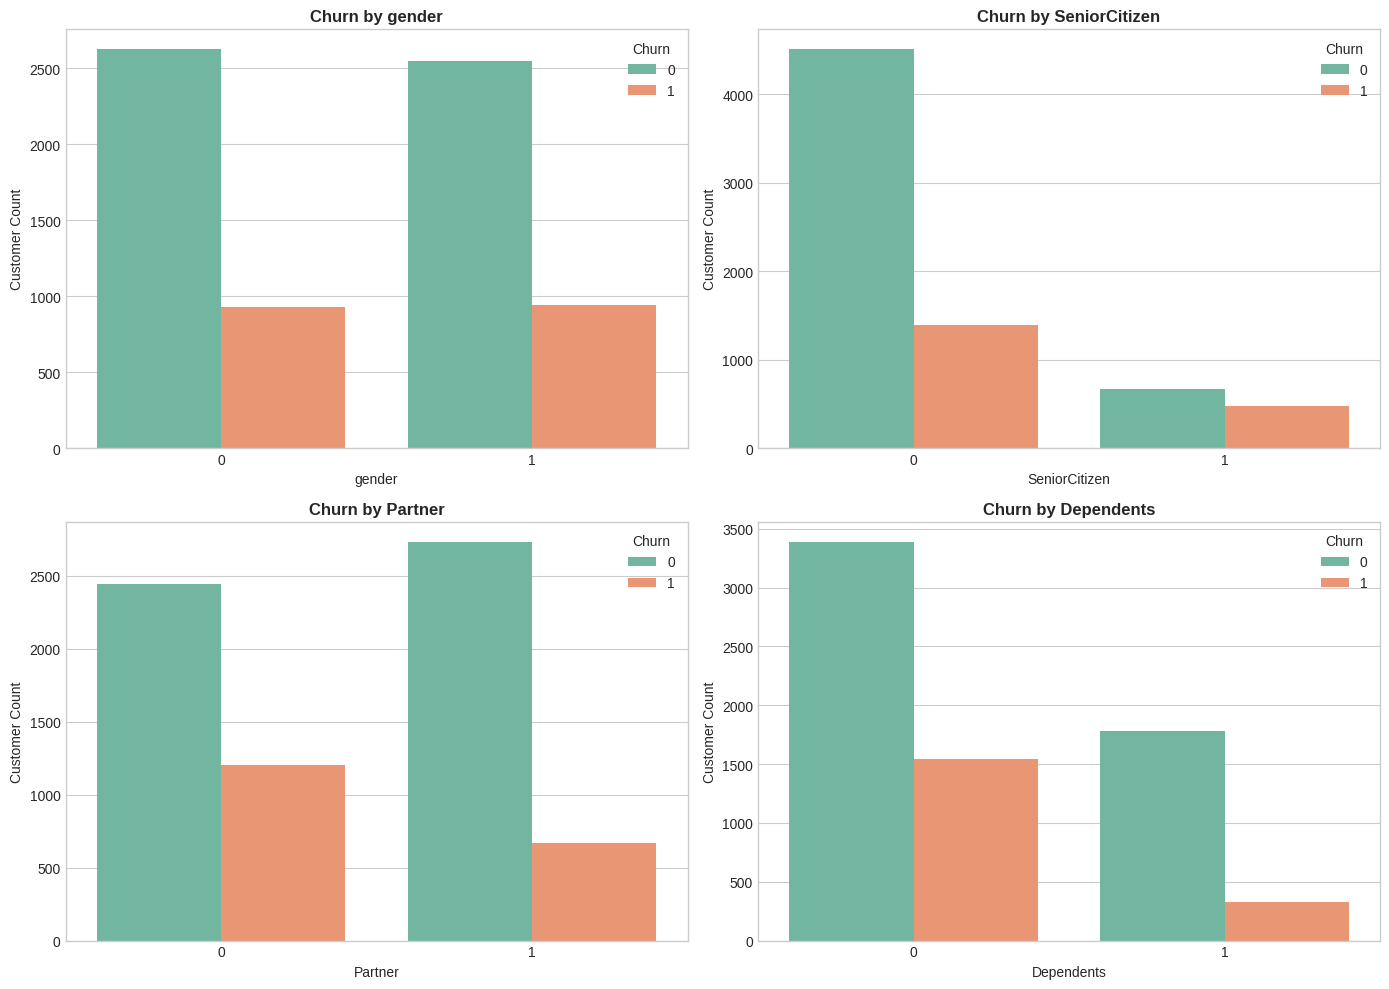

In [75]:
demographic_features = ['gender', 'SeniorCitizen', 'Partner', 'Dependents']

plt.style.use('seaborn-v0_8-whitegrid')
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, feature in enumerate(demographic_features):
    sns.countplot(data=df, x=feature, hue='Churn', ax=axes[i], palette='Set2')
    axes[i].set_title(f'Churn by {feature}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel(feature, fontsize=10)
    axes[i].set_ylabel('Customer Count', fontsize=10)
    axes[i].tick_params(axis='x', rotation=0)
    axes[i].legend(title='Churn', loc='upper right')

plt.tight_layout()
plt.show()

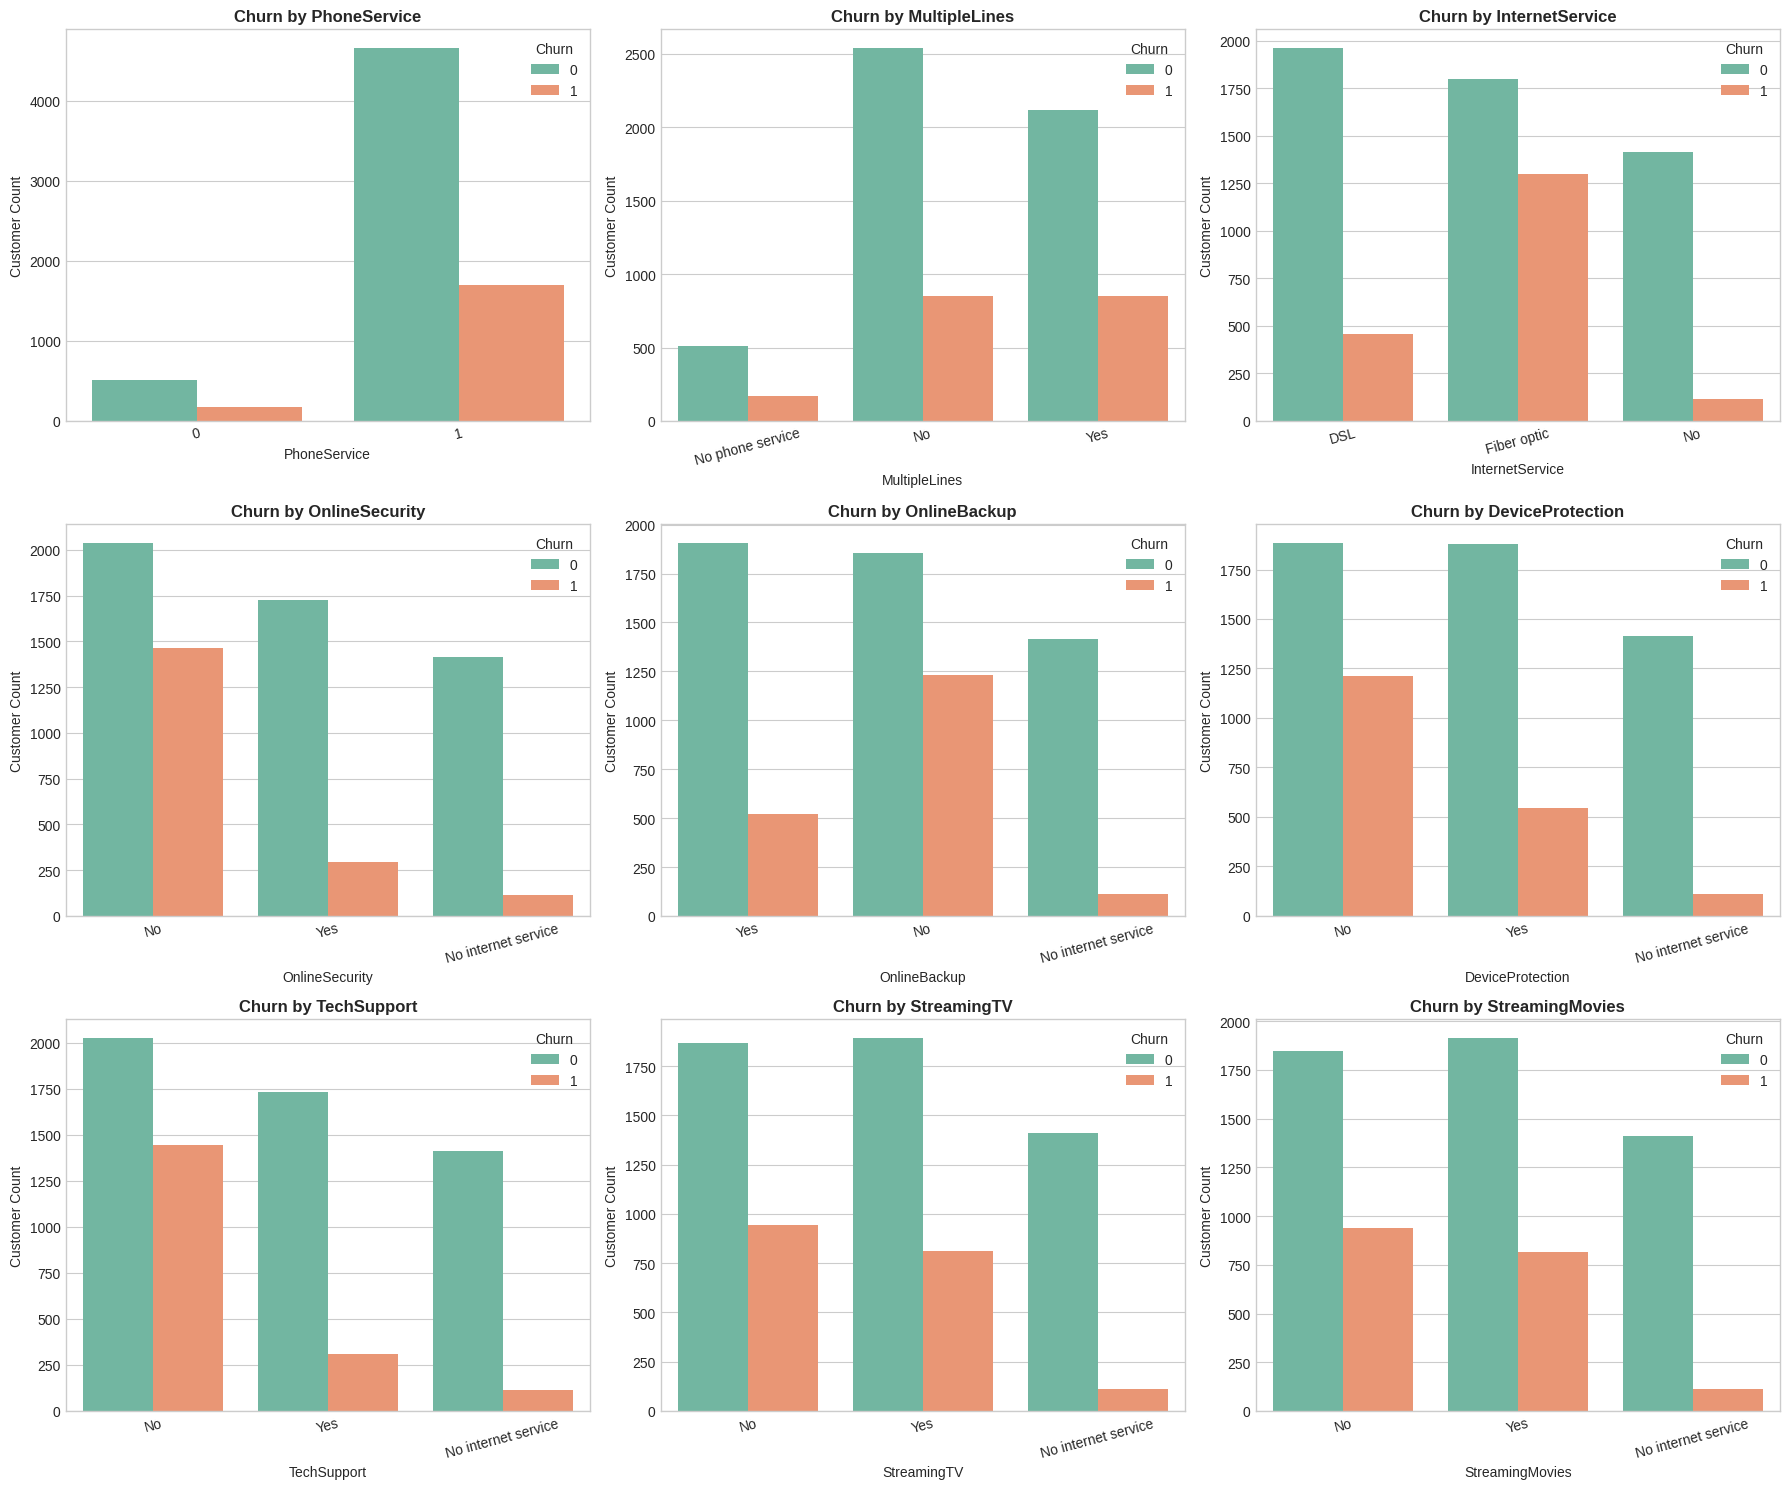

In [76]:
service_features = [
    'PhoneService', 'MultipleLines', 'InternetService',
    'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
    'TechSupport', 'StreamingTV', 'StreamingMovies'
]


plt.style.use('seaborn-v0_8-whitegrid')
fig, axes = plt.subplots(3, 3, figsize=(18, 15))
axes = axes.flatten()


for i, feature in enumerate(service_features):
    sns.countplot(data=df, x=feature, hue='Churn', ax=axes[i], palette='Set2')
    axes[i].set_title(f'Churn by {feature}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel(feature, fontsize=10)
    axes[i].set_ylabel('Customer Count', fontsize=10)
    axes[i].legend(title='Churn', loc='upper right')
    axes[i].tick_params(axis='x', rotation=0)
    axes[i].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

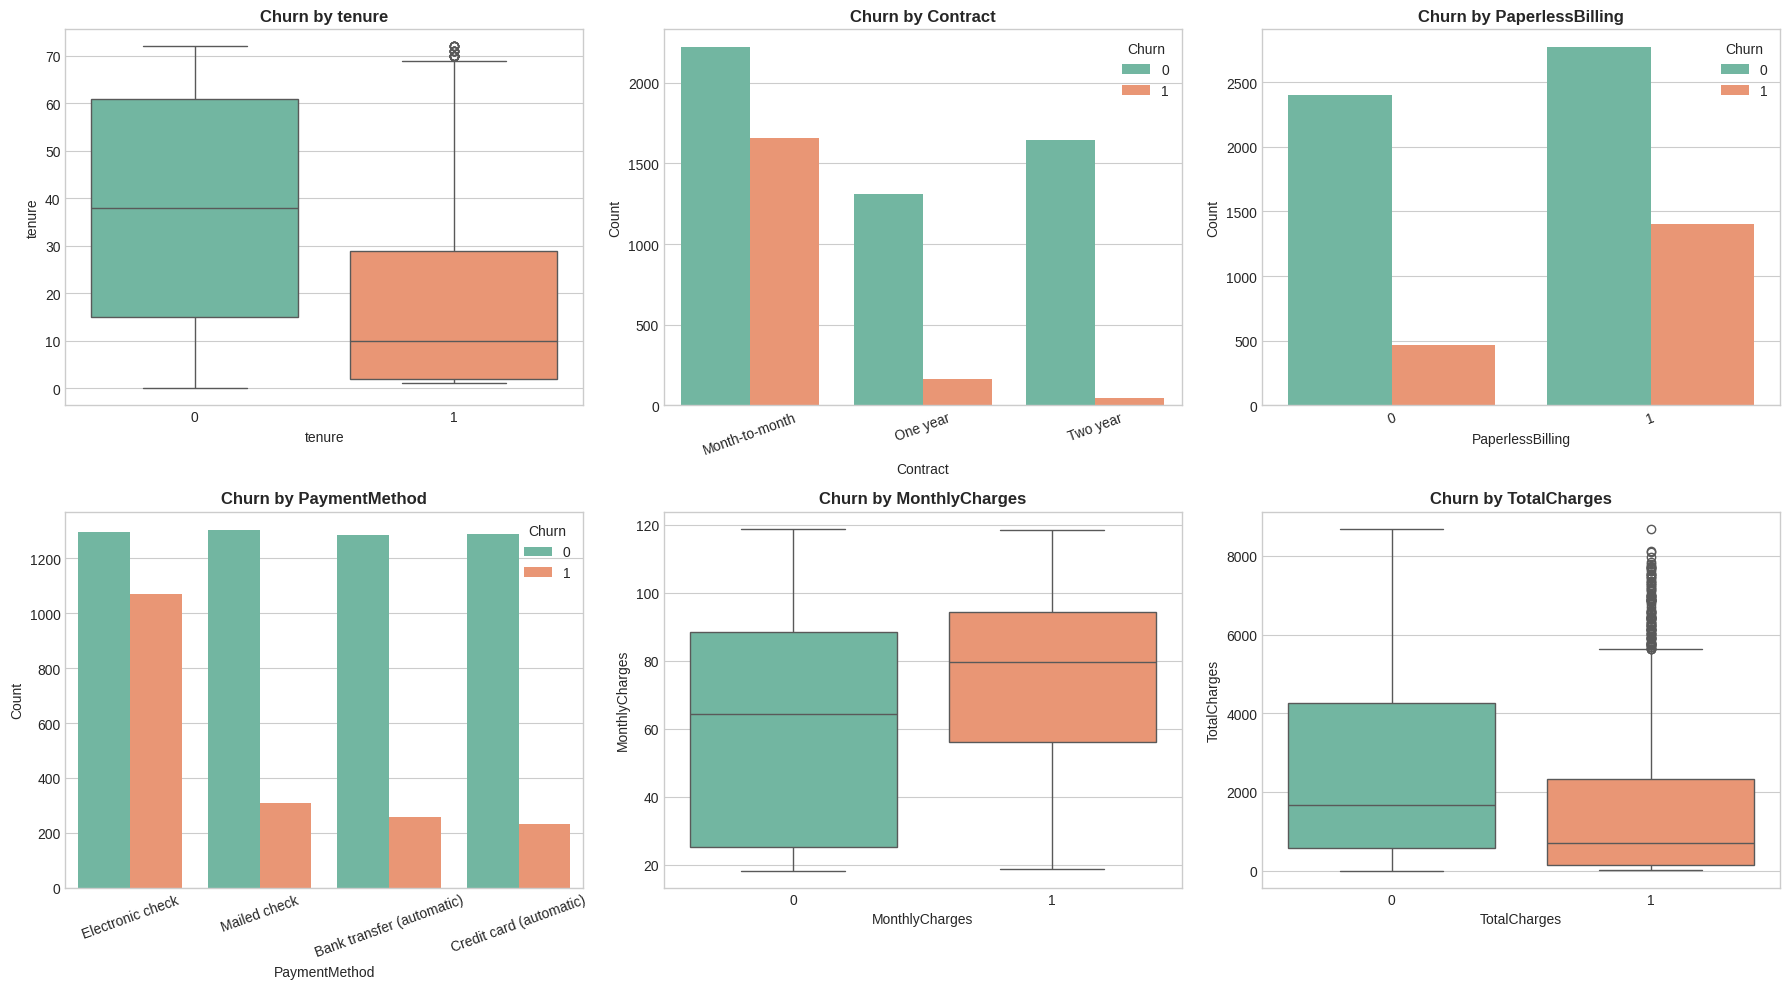

In [77]:
account_features = [
    'tenure',
    'Contract',
    'PaperlessBilling',
    'PaymentMethod',
    'MonthlyCharges',
    'TotalCharges',
]

plt.style.use('seaborn-v0_8-whitegrid')
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, feature in enumerate(account_features):
  if df[feature].dtype == 'object' or df[feature].nunique() < 10:
    sns.countplot(
        data=df, x=feature, hue='Churn', ax=axes[i], palette='Set2'
    )
    axes[i].tick_params(axis='x', rotation=20)
    axes[i].legend(title='Churn', loc='upper right')
    axes[i].set_ylabel('Count', fontsize=10)
  else:
    sns.boxplot(
        data=df,
        x='Churn',
        y=feature,
        hue='Churn',
        ax=axes[i],
        palette='Set2',
        legend=False,
    )
    axes[i].tick_params(axis='x', rotation=0)
    axes[i].set_ylabel(feature, fontsize=10)

  axes[i].set_title(f'Churn by {feature}', fontsize=12, fontweight='bold')
  axes[i].set_xlabel(feature, fontsize=10)

plt.tight_layout()
plt.show()

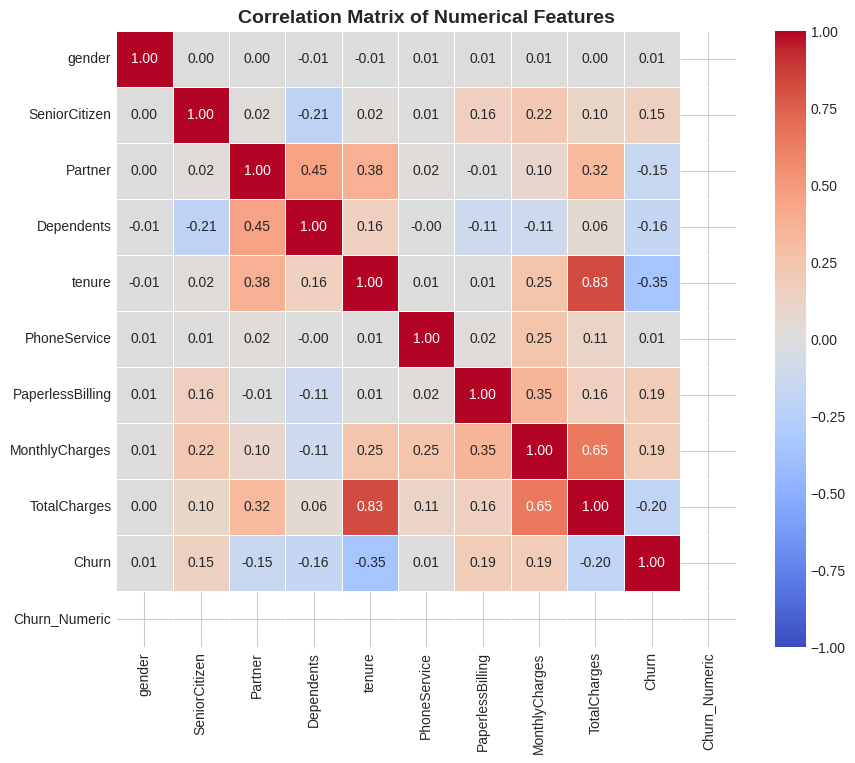

In [78]:
df_corr = df.copy()
if 'Churn' in df_corr.columns:
  df_corr['Churn_Numeric'] = df_corr['Churn'].apply(
      lambda x: 1 if x == 'Yes' else 0
  )

numeric_df = df_corr.select_dtypes(include=['number'])

corr_matrix = numeric_df.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    vmin=-1,
    vmax=1,
)

plt.title('Correlation Matrix of Numerical Features', fontsize=14, fontweight='bold')
plt.show()

In [79]:
df = df.drop(columns=['gender'])
df.shape

(7043, 19)

In [80]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   SeniorCitizen     7043 non-null   int64  
 1   Partner           7043 non-null   int64  
 2   Dependents        7043 non-null   int64  
 3   tenure            7043 non-null   int64  
 4   PhoneService      7043 non-null   int64  
 5   MultipleLines     7043 non-null   object 
 6   InternetService   7043 non-null   object 
 7   OnlineSecurity    7043 non-null   object 
 8   OnlineBackup      7043 non-null   object 
 9   DeviceProtection  7043 non-null   object 
 10  TechSupport       7043 non-null   object 
 11  StreamingTV       7043 non-null   object 
 12  StreamingMovies   7043 non-null   object 
 13  Contract          7043 non-null   object 
 14  PaperlessBilling  7043 non-null   int64  
 15  PaymentMethod     7043 non-null   object 
 16  MonthlyCharges    7043 non-null   float64


## Spliting Data

In [81]:
X = df.drop(columns=['Churn'])
y = df['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print('Shape of X_train:', X_train.shape)
print('Shape of X_test:', X_test.shape)

Shape of X_train: (5634, 18)
Shape of X_test: (1409, 18)


## Feature Engineering

In [82]:
def apply_feature_engineering(data):
  df_fe = data.copy()

  service_cols = [
      'PhoneService',
      'MultipleLines',
      'OnlineSecurity',
      'OnlineBackup',
      'DeviceProtection',
      'TechSupport',
      'StreamingTV',
      'StreamingMovies',
  ]

  existing_services = [col for col in service_cols if col in df_fe.columns]
  df_fe['Total_Services'] = (df_fe[existing_services] == 'Yes').sum(axis=1)

  def tenure_segment(tenure):
    if tenure <= 12:
      return 'New'
    elif tenure <= 36:
      return 'Mid-term'
    else:
      return 'Loyal'

  df_fe['Tenure_Group'] = df_fe['tenure'].apply(tenure_segment)

  return df_fe

X_train_fe = apply_feature_engineering(X_train)
X_test_fe = apply_feature_engineering(X_test)

print(X_train_fe.columns.tolist())

['SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Total_Services', 'Tenure_Group']


## Feature Scaling and Encoding

In [83]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   SeniorCitizen     7043 non-null   int64  
 1   Partner           7043 non-null   int64  
 2   Dependents        7043 non-null   int64  
 3   tenure            7043 non-null   int64  
 4   PhoneService      7043 non-null   int64  
 5   MultipleLines     7043 non-null   object 
 6   InternetService   7043 non-null   object 
 7   OnlineSecurity    7043 non-null   object 
 8   OnlineBackup      7043 non-null   object 
 9   DeviceProtection  7043 non-null   object 
 10  TechSupport       7043 non-null   object 
 11  StreamingTV       7043 non-null   object 
 12  StreamingMovies   7043 non-null   object 
 13  Contract          7043 non-null   object 
 14  PaperlessBilling  7043 non-null   int64  
 15  PaymentMethod     7043 non-null   object 
 16  MonthlyCharges    7043 non-null   float64


In [84]:
numeric_features = [
    'tenure',
    'MonthlyCharges',
    'TotalCharges',
    'Total_Services',
]

categorical_features = [
    'InternetService',
    'MultipleLines',
    'OnlineSecurity',
    'OnlineBackup',
    'DeviceProtection',
    'TechSupport',
    'StreamingTV',
    'StreamingMovies',
    'Contract',
    'PaymentMethod',
    'Tenure_Group',
]

numeric_transformer = Pipeline(steps=[('scaler', StandardScaler())])

categorical_transformer = Pipeline(
    steps=[
        (
            'onehot',
            OneHotEncoder(handle_unknown='ignore', drop='first'),
        )
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features),
    ]
)

In [85]:
X_train_transformed = preprocessor.fit_transform(X_train_fe)
X_test_transformed = preprocessor.transform(X_test_fe)

print(X_train_transformed.shape)
print( X_test_transformed.shape)

(5634, 27)
(1409, 27)


## Training models

In [91]:
models = {
    'Logistic Regression': LogisticRegression(random_state=42, max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
    'XGBoost': XGBClassifier(random_state=42, eval_metric='logloss'),
}

results = {}

for name, model in models.items():
  print(f'================ {name} ================-')

  current_pipeline = Pipeline(
      steps=[('preprocessor', preprocessor), ('classifier', model)]
  )

  current_pipeline.fit(X_train_fe, y_train)

  y_pred = current_pipeline.predict(X_test_fe)

  results[name] = f1_score(y_test, y_pred, pos_label=1)

  print(classification_report(y_test, y_pred, target_names=['No Churn', 'Churn']))
  print('\n')

print('--'*10)
print("Comparing F1-score")
print('--'*10)

for name, score in sorted(results.items(), key=lambda x: x[1], reverse=True):
  print(f'{name}: {score:.4f}')

================ Logistic Regression ================-
              precision    recall  f1-score   support

    No Churn       0.84      0.89      0.86      1035
       Churn       0.63      0.52      0.57       374

    accuracy                           0.79      1409
   macro avg       0.74      0.71      0.72      1409
weighted avg       0.78      0.79      0.79      1409



================ Decision Tree ================-
              precision    recall  f1-score   support

    No Churn       0.82      0.82      0.82      1035
       Churn       0.50      0.49      0.49       374

    accuracy                           0.73      1409
   macro avg       0.66      0.66      0.66      1409
weighted avg       0.73      0.73      0.73      1409



================ Random Forest ================-
              precision    recall  f1-score   support

    No Churn       0.82      0.88      0.85      1035
       Churn       0.59      0.47      0.52       374

    accuracy             

## Hyperparameter Tuning

In [93]:
gb_model = GradientBoostingClassifier(random_state=42)

param_grid = {
    'classifier__n_estimators': [
        50,
        100,
        200,
    ],
    'classifier__learning_rate': [
        0.01,
        0.1,
        0.2,
    ],
    'classifier__max_depth': [3, 4, 5],
}

tuned_pipeline = Pipeline(
    steps=[('preprocessor', preprocessor), ('classifier', gb_model)]
)

param_grid_pipeline = {
    'classifier__n_estimators': [50, 100, 200],
    'classifier__learning_rate': [0.01, 0.1, 0.2],
    'classifier__max_depth': [3, 4, 5],
}

grid_search = GridSearchCV(
    estimator=tuned_pipeline,
    param_grid=param_grid_pipeline,
    cv=5,
    scoring='f1',
    n_jobs=-1,
    verbose=1,
)

grid_search.fit(X_train_fe, y_train)

print('Best Hyperparameters')
print(grid_search.best_params_)

best_model = grid_search.best_estimator_
y_pred_tuned = best_model.predict(X_test_fe)

print('Classification report')
print(classification_report(y_test, y_pred_tuned, target_names=['No Churn', 'Churn']))

Fitting 5 folds for each of 27 candidates, totalling 135 fits
Best Hyperparameters
{'classifier__learning_rate': 0.1, 'classifier__max_depth': 3, 'classifier__n_estimators': 100}
Classification report
              precision    recall  f1-score   support

    No Churn       0.84      0.91      0.87      1035
       Churn       0.66      0.51      0.57       374

    accuracy                           0.80      1409
   macro avg       0.75      0.71      0.72      1409
weighted avg       0.79      0.80      0.79      1409



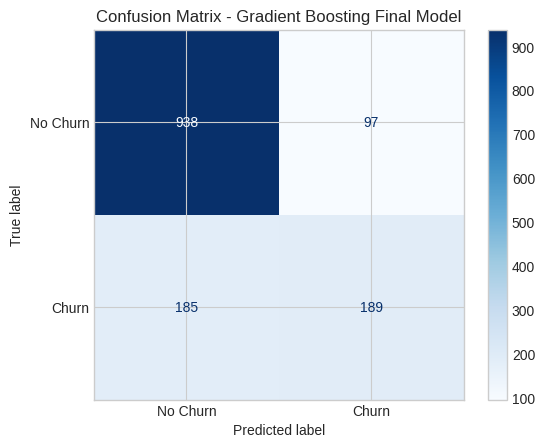

In [96]:
ConfusionMatrixDisplay.from_estimator(
    best_model, X_test_fe, y_test, display_labels=['No Churn', 'Churn'], cmap='Blues'
)
plt.title('Confusion Matrix - Gradient Boosting Final Model')
plt.show()